In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pylabdd as dd



Running system command with arguments
   gfortran PK_force.f90 PK_force_c_wrapper.f90 -fPIC -shared -O3 -o PK_force.arm64.so


ld: warning: duplicate -rpath '/opt/miniconda3/envs/pylabdd/lib' ignored
ld: warning: duplicate -rpath '/opt/miniconda3/envs/pylabdd/lib' ignored




Running system command with arguments
   gfortran mod_gbdd.f90 mod_gbdd_c_wrapper.f90 -fPIC -shared -O3 -o mod_gbdd.arm64.so


ld: warning: duplicate -rpath '/opt/miniconda3/envs/pylabdd/lib' ignored
ld: warning: duplicate -rpath '/opt/miniconda3/envs/pylabdd/lib' ignored


In [1]:
temp = 600.0
tau0 = 0.0
lgb = 0.1
grain_size = 1.0
maxout = 1000
tfin = 2.e4
niter = 100_000_000
#ngbn = 41 #int(lgb/delta)
#if ngbn % 2 == 0: ngbn += 1
ngb_list = [11, 21, 31, 41]
Np = len(ngb_list)
bdmax = np.zeros((Np, maxout))
btot = np.zeros((Np, maxout))
sim_time = np.zeros((Np, maxout))
nit = np.zeros(Np, dtype=int)
Ngb_list = np.zeros(Np, dtype=int)
for i, ngbn in enumerate(ngb_list):
    delta = lgb/(ngbn - 1)  # 0.005
    dtmax = 1.e-3 # 6.25e-20/delta**4  # value 1.e4 for delta=0.005, 50. for PU
    print(f"Simulation with N_gbn={ngbn}, delta={delta}, dtmax={dtmax}")
    gbdd = dd.GB_dislocations(temp=temp, tau0=tau0,
                       Ngbn=ngbn, len_gb_seg=lgb, grain_size=grain_size,
                       tfin=tfin, niter=niter, maxout=maxout,
                       dtmax=dtmax,
                       screenout=True)
    gbdd.run_sim()
    gbdd.plot_time_series(['timestep', 'n_gbdis_eff'])
    #gbdd.plot_time_series('max_bdot')
    gbdd.plot_field('displacement')
    #gbdd.plot_field('flux')
    nit[i] = gbdd.nout
    Ngb_list[i] = gbdd.Ngbn
    sim_time[i, 0:gbdd.nout] = gbdd.sim_time
    bdmax[i, 0:gbdd.nout] = gbdd.glob_data['max_bdot']
    btot[i, 0:gbdd.nout] = gbdd.glob_data['n_gbdis_eff']

NameError: name 'np' is not defined

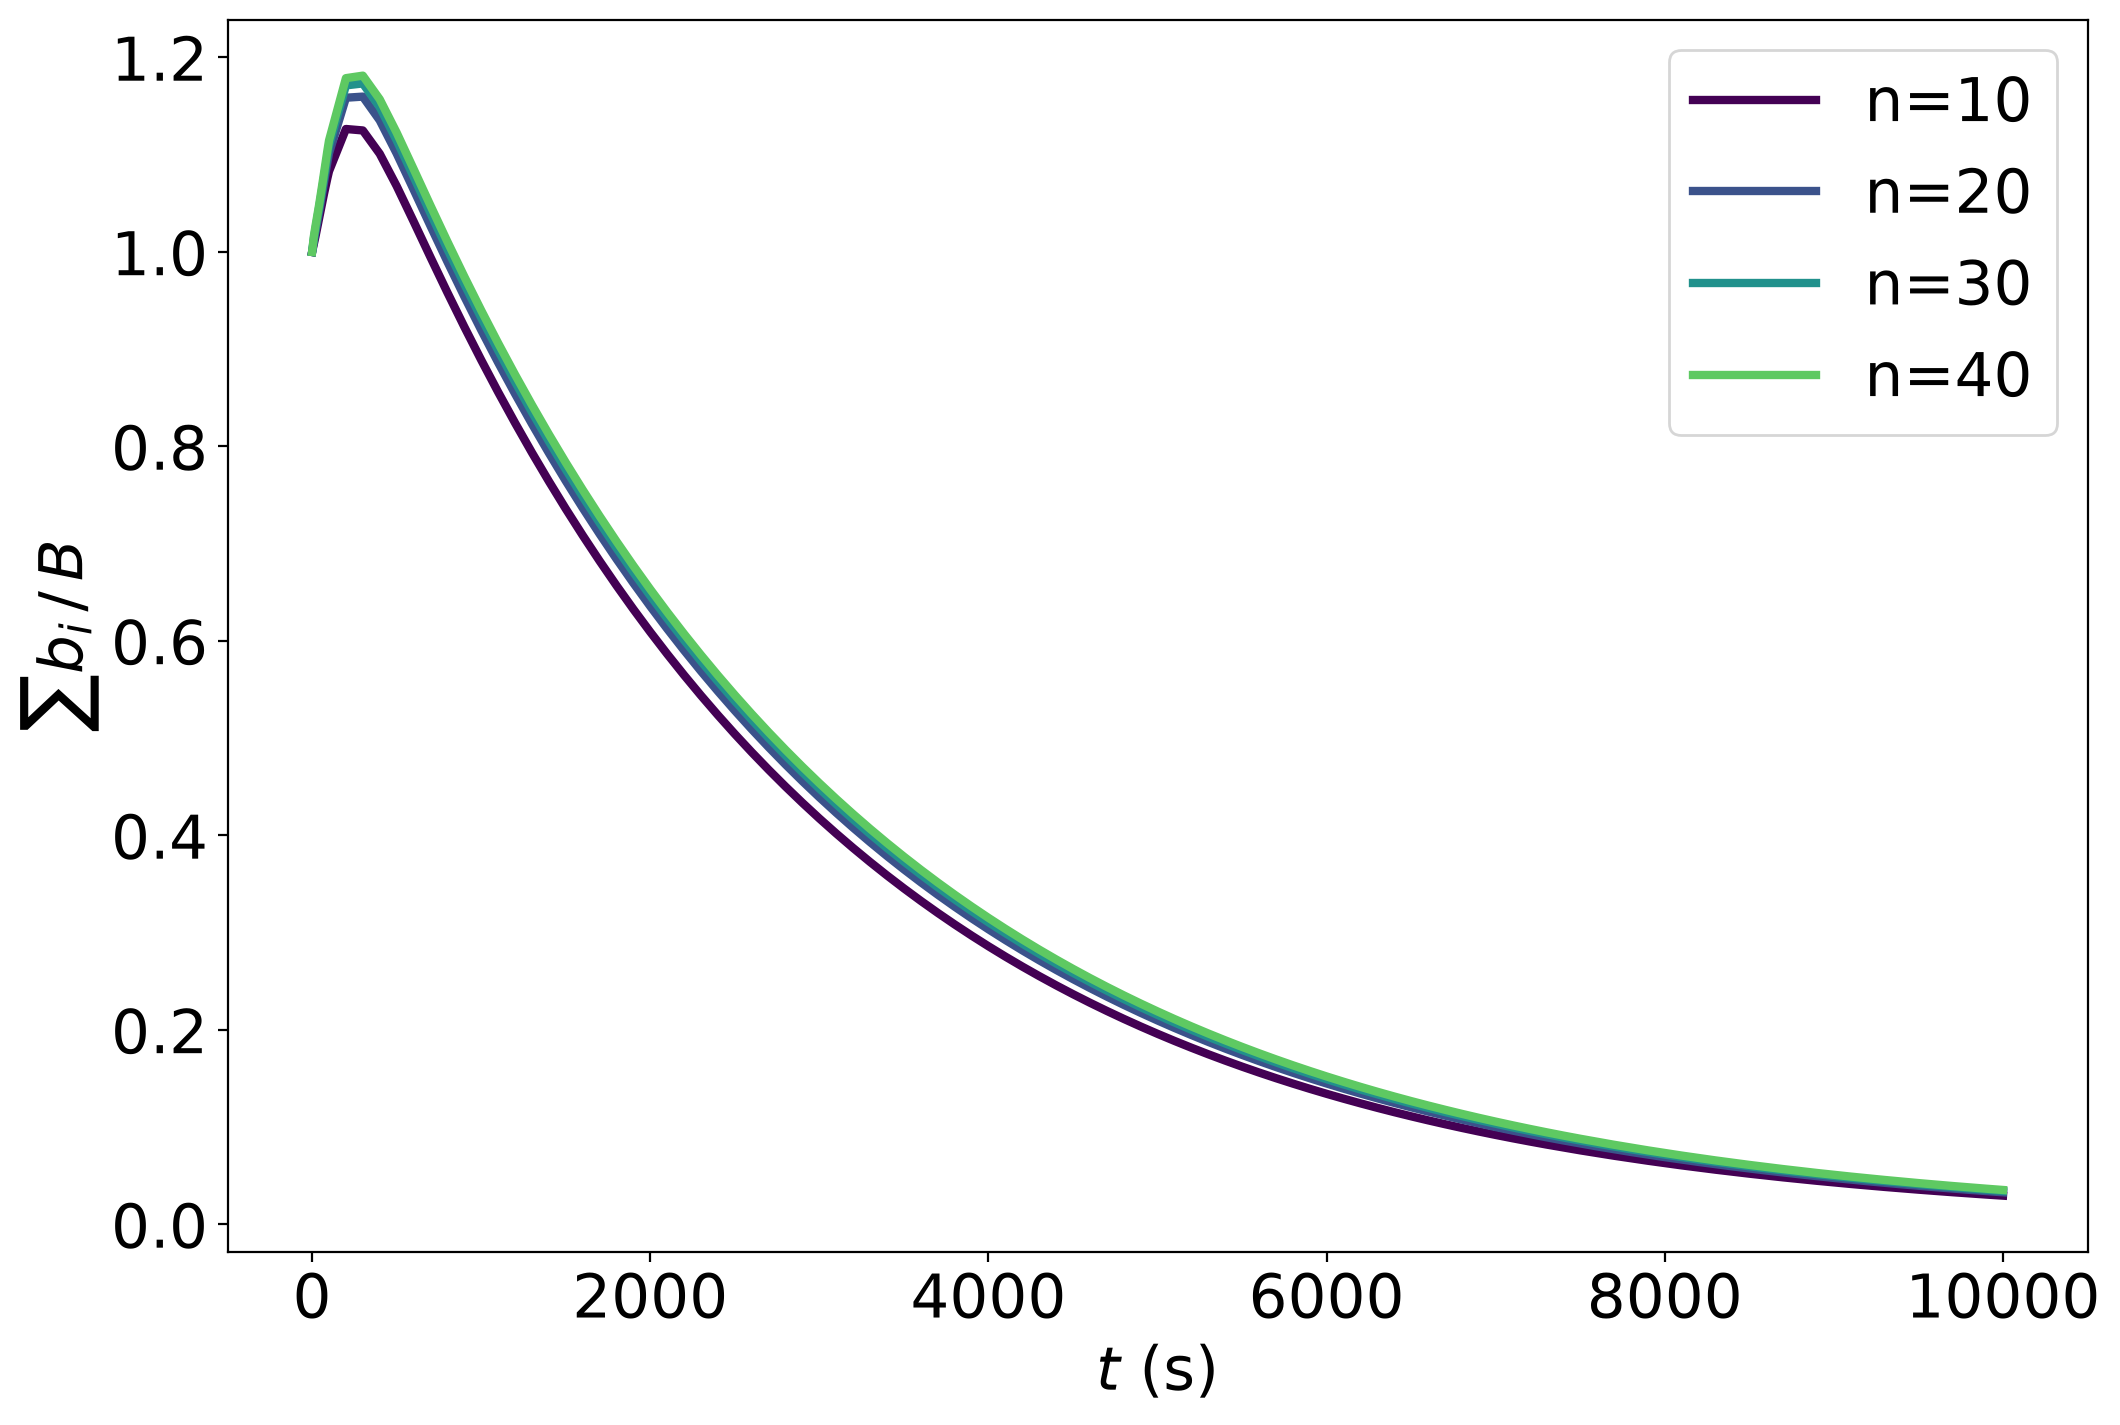

In [7]:
plt.rcParams["font.size"] = 22
fig, ax = plt.subplots(figsize=(12, 8), dpi=200)
for i in range(Np):
    plt.plot(sim_time[i, :nit[i]],
             btot[i, :nit[i]],
             marker="none",
             linestyle="-",
             linewidth=3,
             color=plt.cm.viridis(i / max(1, Np)),
             label=f"n={Ngb_list[i]-1}"
             )
plt.legend()
plt.xlabel(r"$t$ (s)")
plt.ylabel(r"$\sum b_i \,/ \,B$")
plt.savefig('F03_conv_gb01_ngbn.pdf', dpi=300, format='pdf')
plt.show()

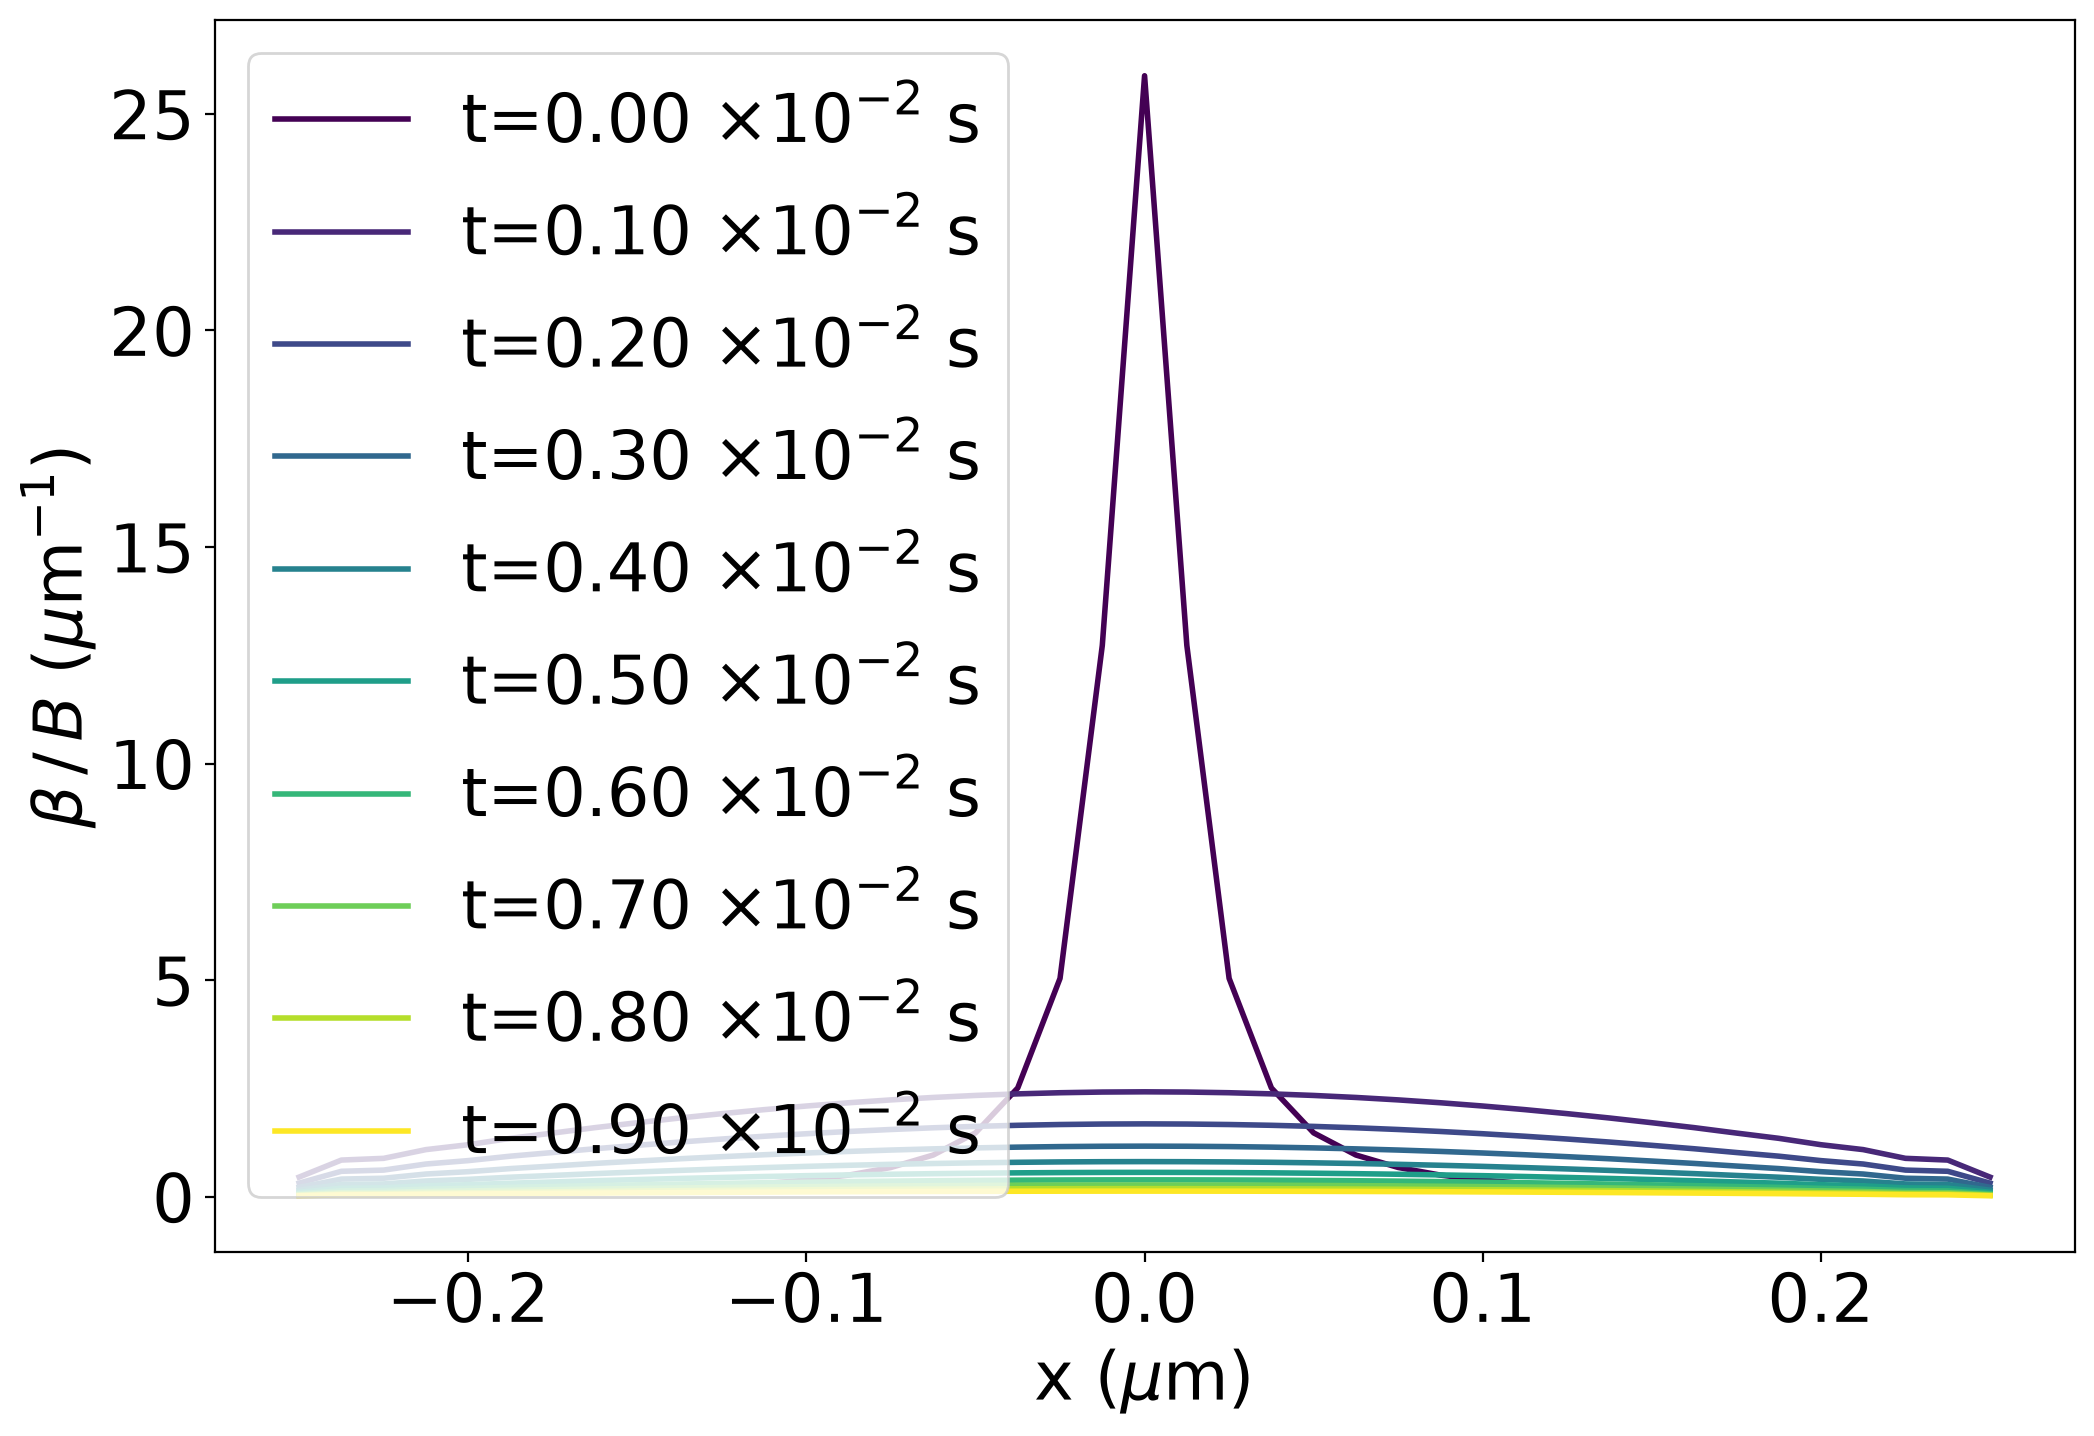

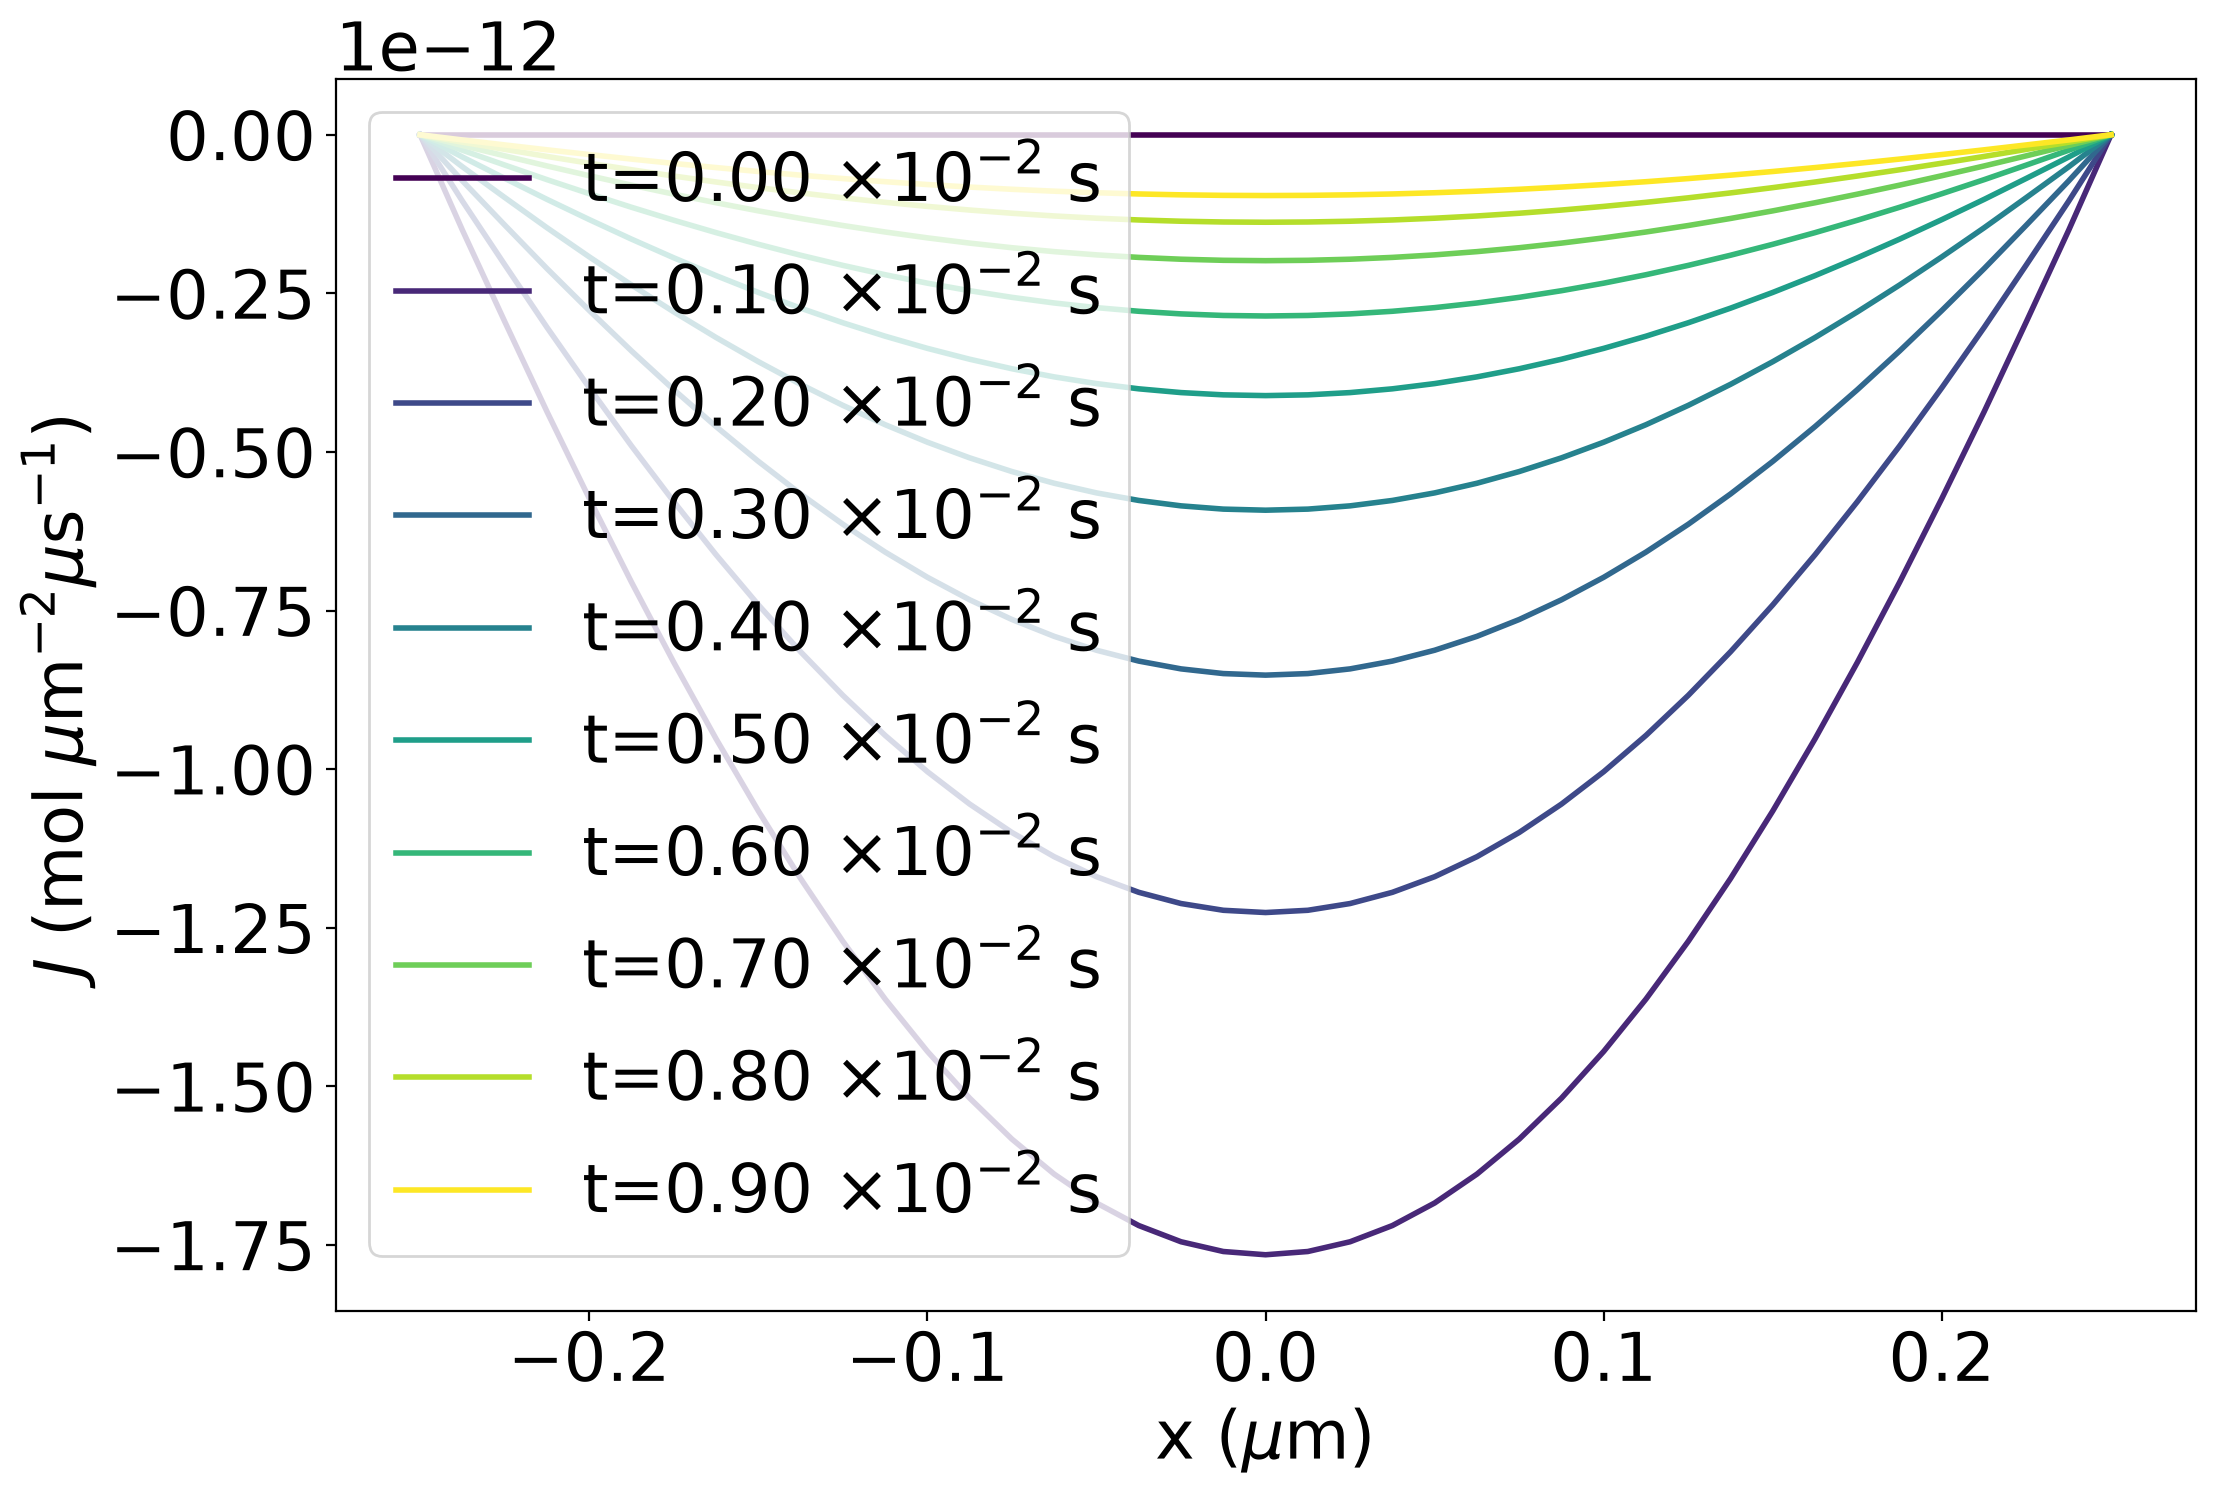

In [10]:
gbdd.plot_field("beta")
gbdd.plot_field("flux")